<a href="https://colab.research.google.com/github/panidasrs/chest-xray-ai/blob/main/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: Chest X-Ray Images (Pneumonia)

Run on Colab (no GPU needed). Downloads the data and makes `splits.csv` first.

In [1]:
!git clone https://github.com/panidasrs/chest-xray-ai.git
%cd chest-xray-ai
!pip install -q kagglehub
!python prepare_data.py

Cloning into 'chest-xray-ai'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 50 (delta 18), reused 43 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 1.66 MiB | 4.50 MiB/s, done.
Resolving deltas: 100% (18/18), done.
/content/chest-xray-ai
100% 2.29G/2.29G [00:27<00:00, 90.2MB/s]
Extracting files...
Data folder: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray
label  normal  pneumonia
split                   
test      234        390
train    1146       3311
val       203        572
Saved splits.csv


## 1. How many images are in each split and class?

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

os.makedirs("results", exist_ok=True)
df = pd.read_csv("splits.csv")
df["class"] = df["label"].map({0: "normal", 1: "pneumonia"})

counts = df.groupby(["split", "class"]).size().unstack().loc[["train", "val", "test"]]
counts["pneumonia %"] = (100 * counts["pneumonia"] / counts.sum(axis=1)).round(1)
counts

class,normal,pneumonia,pneumonia %
split,,,
train,1146,3311,74.3
val,203,572,73.8
test,234,390,62.5


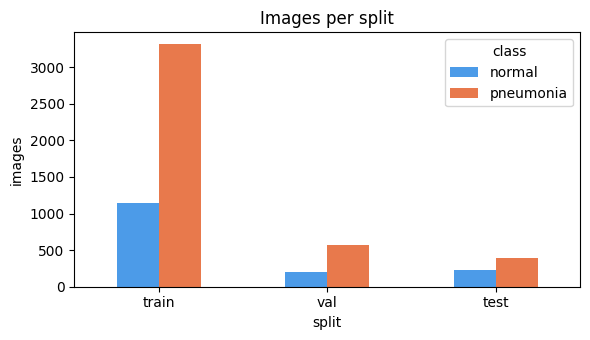

In [3]:
counts[["normal", "pneumonia"]].plot.bar(rot=0, figsize=(6, 3.5), color=["#4c9be8", "#e8794c"])
plt.title("Images per split")
plt.ylabel("images")
plt.tight_layout()
plt.savefig("results/eda_class_balance.png", dpi=120)
plt.show()

## 2. Pneumonia type (from the file name)

Pneumonia file names contain `bacteria` or `virus`. The model only predicts normal vs pneumonia, but it is useful to know the mix.

In [4]:
pneu = df[df["label"] == 1].copy()
pneu["type"] = np.where(pneu["path"].str.contains("virus"), "virus", "bacteria")
pneu.groupby(["split", "type"]).size().unstack()

type,bacteria,virus
split,,
test,242,148
train,2158,1153
val,380,192


## 3. How many images per patient?

This is why the train/val split is done by patient: some children have several X-rays.

In [5]:
per_patient = df[df["split"] != "test"].groupby(["class", "patient"]).size()
print(per_patient.groupby("class").describe()[["count", "mean", "max"]])

per_patient.groupby("class").value_counts().unstack(0).head(6)

            count      mean   max
class                            
normal     1286.0  1.048989   3.0
pneumonia  1642.0  2.364799  30.0


class,normal,pneumonia
1,1226.0,636.0
2,57.0,562.0
3,3.0,191.0
4,NaN,85.0
5,NaN,43.0
6,NaN,44.0


## 4. Image size and color mode

Images are resized to 224x224 for the model, so it is worth checking how big and how different they are.

In [6]:
rows = []
for path in df["path"]:
    with Image.open(path) as img:  # opening is fast, pixels are not loaded
        rows.append({"width": img.size[0], "height": img.size[1], "mode": img.mode})
sizes = pd.concat([df[["split", "class"]].reset_index(drop=True), pd.DataFrame(rows)], axis=1)
sizes["aspect"] = (sizes["width"] / sizes["height"]).round(2)

print(sizes["mode"].value_counts(), "\n")
sizes.groupby("class")[["width", "height", "aspect"]].describe().T.round(1)

mode
L      5573
RGB     283
Name: count, dtype: int64 



class         normal  pneumonia
width  count  1583.0     4273.0
       mean   1686.4     1195.1
       std     305.3      285.1
       min     912.0      384.0
       25%    1472.0     1000.0
       50%    1654.0     1160.0
       75%    1848.0     1360.0
       max    2916.0     2772.0
height count  1583.0     4273.0
       mean   1378.6      819.6
       std     343.0      270.9
       min     496.0      127.0
       25%    1140.0      640.0
       50%    1323.0      776.0
       75%    1554.0      960.0
       max    2713.0     2304.0
aspect count  1583.0     4273.0
       mean      1.2        1.5
       std       0.2        0.2
       min       0.9        0.8
       25%       1.1        1.4
       50%       1.2        1.5
       75%       1.3        1.6
       max       2.1        3.4

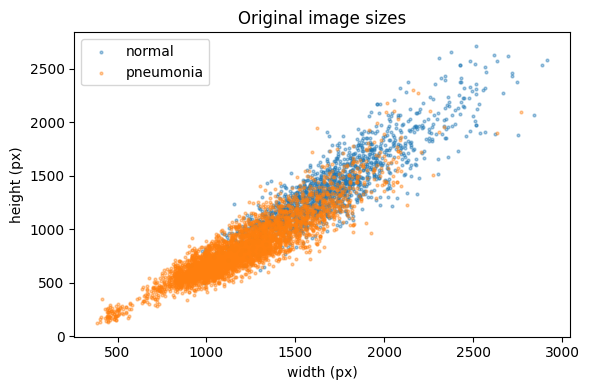

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, g in sizes.groupby("class"):
    ax.scatter(g["width"], g["height"], s=4, alpha=0.4, label=name)
ax.set_xlabel("width (px)")
ax.set_ylabel("height (px)")
ax.set_title("Original image sizes")
ax.legend()
plt.tight_layout()
plt.savefig("results/eda_image_sizes.png", dpi=120)
plt.show()

## 5. Example images

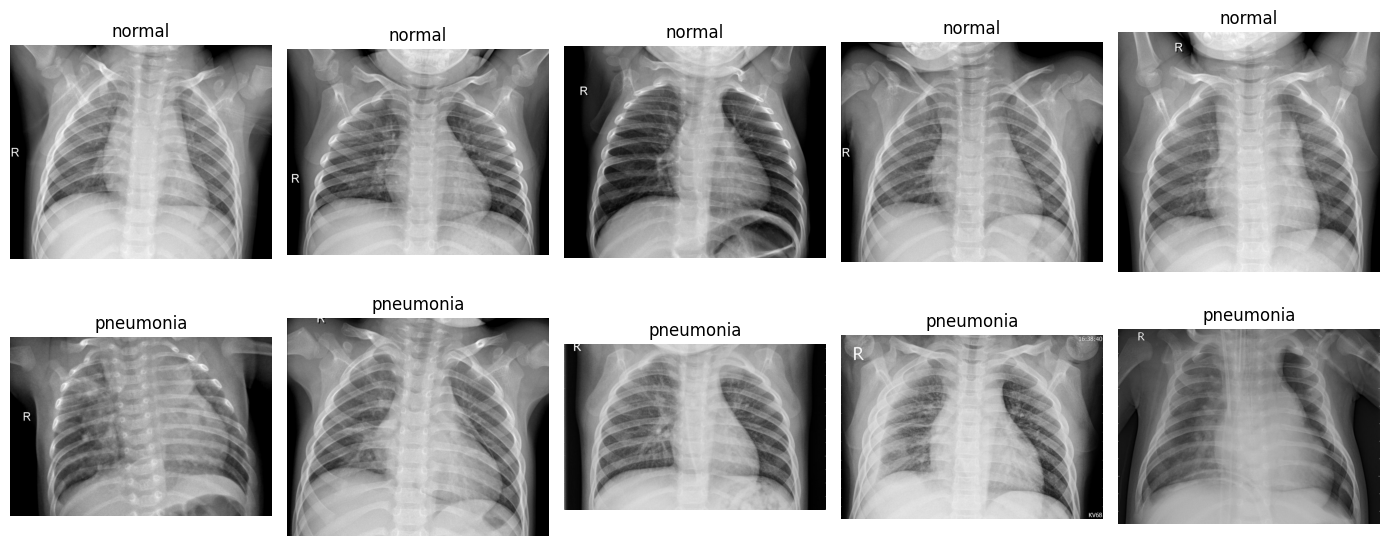

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, (name, g) in enumerate(df[df["split"] == "train"].groupby("class")):
    for col, path in enumerate(g.sample(5, random_state=1)["path"]):
        axes[row, col].imshow(Image.open(path).convert("L"), cmap="gray")
        axes[row, col].set_title(name)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("results/eda_examples.png", dpi=100)
plt.show()

## 6. Brightness per class

If the two classes have very different brightness, the model could learn brightness instead of the disease (a shortcut).

           count   mean   std   min    25%    50%    75%    max
class                                                          
normal     300.0  123.0  13.5  83.8  114.6  122.9  131.0  159.3
pneumonia  300.0  122.7  20.2  69.2  109.5  122.9  136.6  172.7


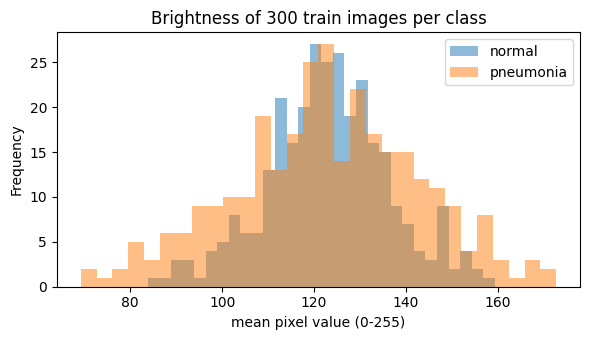

In [9]:
def mean_brightness(path):
    with Image.open(path) as img:
        return np.asarray(img.convert("L").resize((224, 224))).mean()

sample = df[df["split"] == "train"].groupby("class").sample(300, random_state=0)
sample["brightness"] = sample["path"].apply(mean_brightness)

print(sample.groupby("class")["brightness"].describe().round(1))
sample.groupby("class")["brightness"].plot.hist(bins=30, alpha=0.5, legend=True, figsize=(6, 3.5))
plt.xlabel("mean pixel value (0-255)")
plt.title("Brightness of 300 train images per class")
plt.tight_layout()
plt.savefig("results/eda_brightness.png", dpi=120)
plt.show()

## 7. What I learned

- **Class balance:** about 74% pneumonia in train and val, but only 62.5% in test.
  The test set has a different class mix, which is one reason the threshold chosen on validation
  doesn't transfer perfectly.
- **Images per patient:** normal patients have about __ image(s) each, pneumonia patients about __ (max __).
  This is why train/val is split by patient.
- **Image sizes:** normal images are much bigger (median 1654x1323) than pneumonia images (median 1160x776),
  and the shape is different (width/height 1.2 vs 1.5). Resizing everything to 224x224 squashes the two
  classes differently, so the model could learn the image shape instead of the disease. This may connect
  to the Grad-CAM result (attention on borders).
- **Color mode:** 283 of 5,856 images are RGB, the rest grayscale. All images are converted to grayscale.
- **Brightness:** mean brightness is almost the same for both classes (123.0 vs 122.7), so average
  brightness is probably not a shortcut. Pneumonia images vary more (std 20.2 vs 13.5).